## ✍️ Exercice 3 — Graphiques (créer le DataFrame)

1. Histogramme du `chiffre_affaires` avec `kde=True`. Que remarques-tu sur la forme ?
2. Boxplot du CA par catégorie. Y a-t-il des valeurs aberrantes ?
3. Courbe du CA mensuel (Matplotlib orienté objet, avec titre, axes et grille).
4. Barplot du CA total par ville, trié du plus grand au plus petit.
5. Heatmap de corrélation entre `quantite`, `prix_unitaire` et `chiffre_affaires`. Interprète.
6. Une figure à 2 sous-graphiques côte à côte (histogramme + boxplot de la même variable).
7. Sauvegarde ta figure en PNG à 300 dpi.
8. **Bonus** : pour chaque graphique, écris en une phrase le **message** qu'il transmet à un décideur.

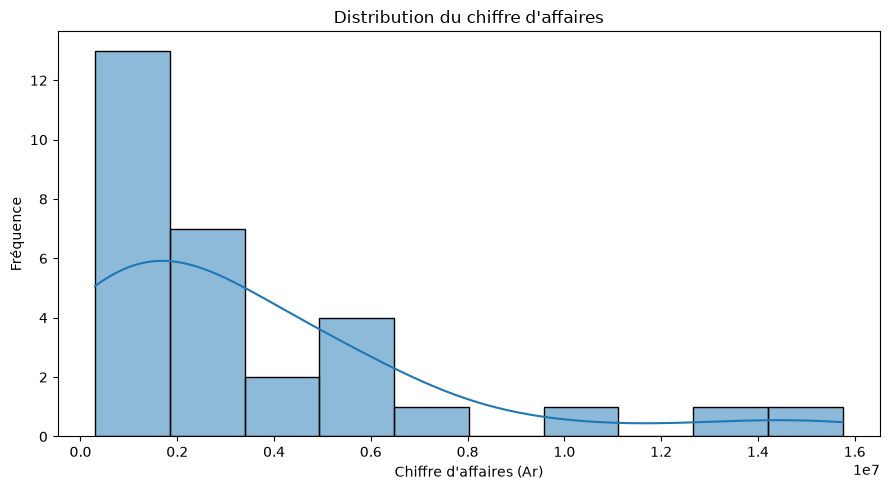

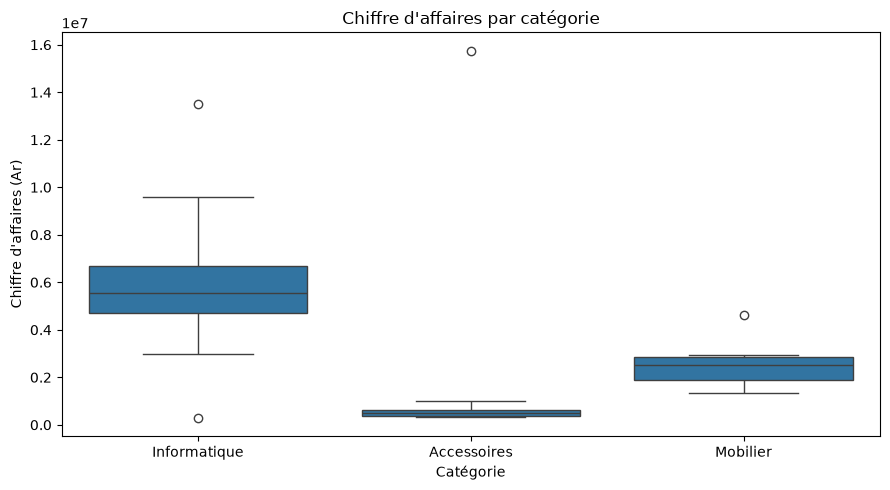

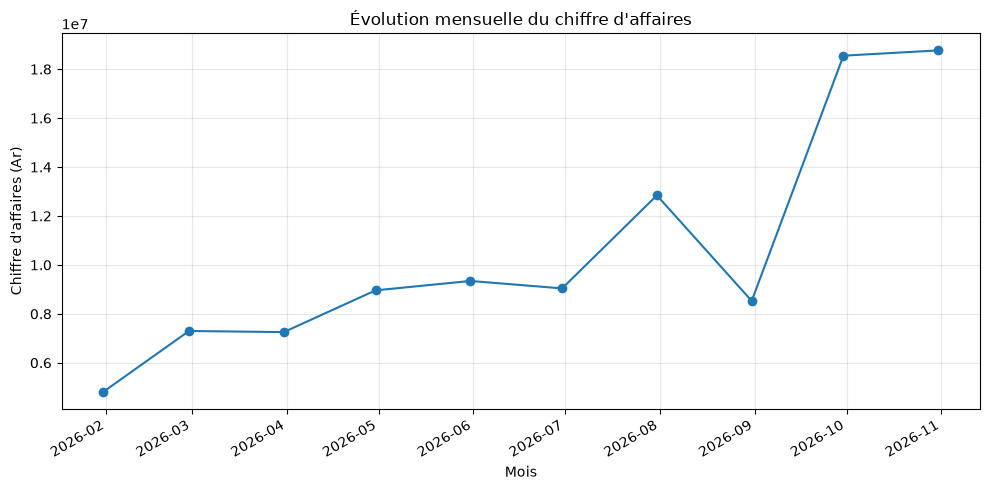

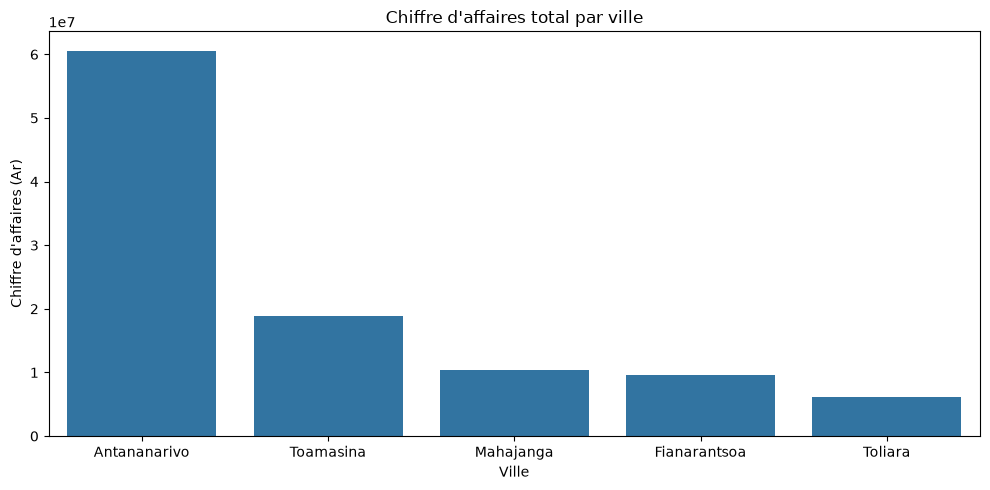

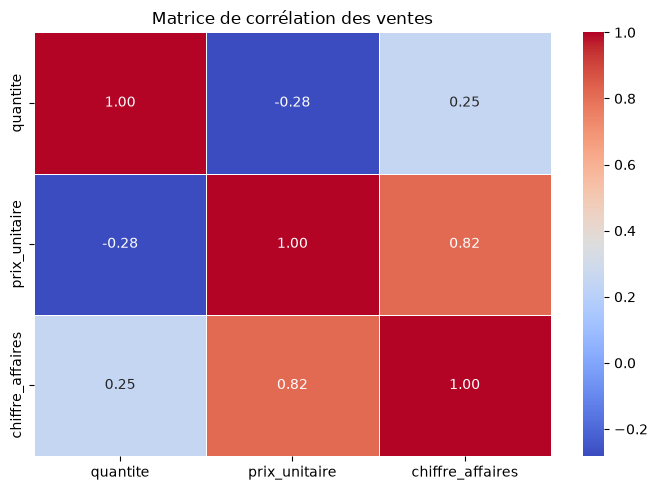


Matrice de corrélation :
                  quantite  prix_unitaire  chiffre_affaires
quantite          1.000000      -0.281485          0.251662
prix_unitaire    -0.281485       1.000000          0.816958
chiffre_affaires  0.251662       0.816958          1.000000


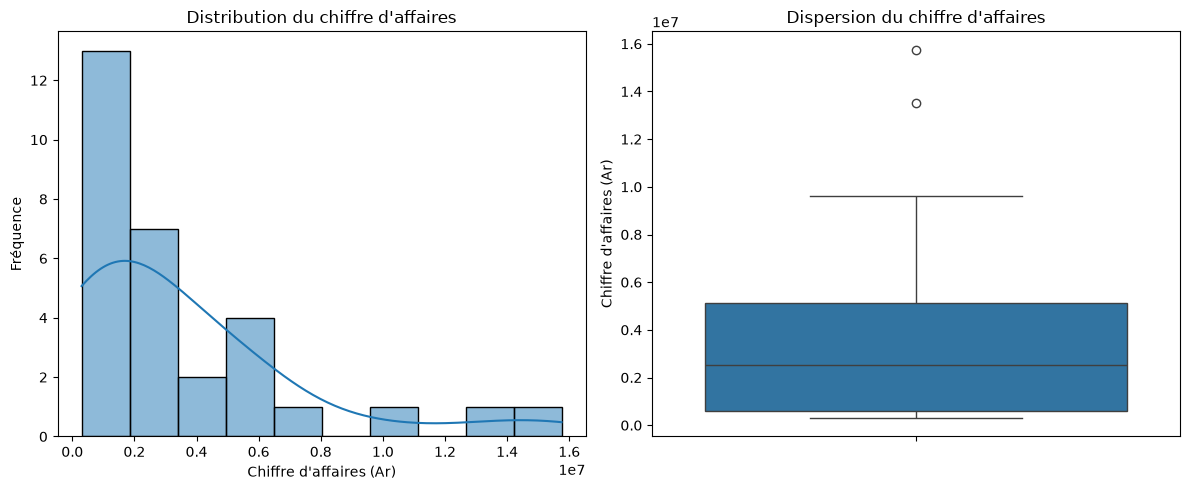


Figure sauvegardée avec succès !

MESSAGES POUR UN DÉCIDEUR

1. Histogramme :
   Identifier la répartition du chiffre d'affaires
   et les niveaux de ventes les plus fréquents.

2. Boxplot par catégorie :
   Comparer la dispersion du chiffre d'affaires
   et repérer les ventes exceptionnellement élevées.

3. Courbe mensuelle :
   Suivre l'évolution du chiffre d'affaires
   et identifier les mois les plus performants.

4. Barplot par ville :
   Identifier les villes qui contribuent le plus
   au chiffre d'affaires total.

5. Heatmap :
   Examiner les relations entre quantité,
   prix unitaire et chiffre d'affaires.

6. Histogramme et boxplot :
   Obtenir une vue complémentaire de la distribution
   et des valeurs atypiques du chiffre d'affaires.

14/18 , 14 réponses correctes sur un QCM de 18 questions


In [1]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



donnees = {
    "date": [
        "2026-01-05", "2026-01-12", "2026-01-20",
        "2026-02-03", "2026-02-14", "2026-02-25",
        "2026-03-02", "2026-03-11", "2026-03-22",
        "2026-04-04", "2026-04-15", "2026-04-27",
        "2026-05-06", "2026-05-17", "2026-05-28",
        "2026-06-03", "2026-06-14", "2026-06-26",
        "2026-07-05", "2026-07-16", "2026-07-29",
        "2026-08-02", "2026-08-13", "2026-08-24",
        "2026-09-04", "2026-09-15", "2026-09-26",
        "2026-10-03", "2026-10-14", "2026-10-25"
    ],
    "ville": [
        "Antananarivo", "Toamasina", "Mahajanga",
        "Antananarivo", "Fianarantsoa", "Toamasina",
        "Mahajanga", "Antananarivo", "Toliara",
        "Toamasina", "Antananarivo", "Fianarantsoa",
        "Mahajanga", "Toliara", "Antananarivo",
        "Fianarantsoa", "Toamasina", "Antananarivo",
        "Toliara", "Mahajanga", "Antananarivo",
        "Toamasina", "Fianarantsoa", "Mahajanga",
        "Antananarivo", "Toliara", "Toamasina",
        "Fianarantsoa", "Antananarivo", "Mahajanga"
    ],
    "categorie": [
        "Informatique", "Accessoires", "Mobilier",
        "Informatique", "Accessoires", "Mobilier",
        "Accessoires", "Informatique", "Mobilier",
        "Mobilier", "Informatique", "Accessoires",
        "Informatique", "Mobilier", "Accessoires",
        "Accessoires", "Informatique", "Mobilier",
        "Mobilier", "Accessoires", "Informatique",
        "Informatique", "Mobilier", "Accessoires",
        "Accessoires", "Informatique", "Mobilier",
        "Mobilier", "Informatique", "Accessoires"
    ],
    "quantite": [
        12, 25, 8, 15, 30, 10, 18, 20, 7, 14,
        16, 35, 22, 9, 28, 40, 19, 11, 13, 32,
        24, 17, 12, 27, 45, 15, 10, 21, 30, 38
    ],
    "prix_unitaire": [
        250000, 15000, 180000, 300000, 20000,
        220000, 18000, 280000, 190000, 210000,
        350000, 12000, 320000, 200000, 18000,
        25000, 290000, 230000, 210000, 16000,
        400000, 310000, 240000, 14000, 350000,
        20000, 250000, 220000, 450000, 17000
    ]
}

ventes = pd.DataFrame(donnees)

ventes["date"] = pd.to_datetime(ventes["date"])

ventes["chiffre_affaires"] = (
    ventes["quantite"] * ventes["prix_unitaire"]
)



# 2. HISTOGRAMME DU CHIFFRE D'AFFAIRES

plt.figure(figsize=(9, 5))

sns.histplot(
    data=ventes,
    x="chiffre_affaires",
    bins=10,
    kde=True
)

plt.title("Distribution du chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (Ar)")
plt.ylabel("Fréquence")

plt.tight_layout()
plt.show()



# 3. BOXPLOT DU CA PAR CATÉGORIE
   

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=ventes,
    x="categorie",
    y="chiffre_affaires"
)

plt.title("Chiffre d'affaires par catégorie")
plt.xlabel("Catégorie")
plt.ylabel("Chiffre d'affaires (Ar)")

plt.tight_layout()
plt.show()


   
# 4. COURBE DU CA MENSUEL
   

ventes_mensuelles = (
    ventes.set_index("date")
    .resample("ME")["chiffre_affaires"]
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ventes_mensuelles.index,
    ventes_mensuelles.values,
    marker="o",
    linestyle="-"
)

ax.set_title("Évolution mensuelle du chiffre d'affaires")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires (Ar)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


   
# 5. BARPLOT DU CA TOTAL PAR VILLE
   

ca_ville = (
    ventes.groupby("ville")["chiffre_affaires"]
    .sum()
    .reset_index()
    .sort_values("chiffre_affaires", ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ca_ville,
    x="ville",
    y="chiffre_affaires"
)

plt.title("Chiffre d'affaires total par ville")
plt.xlabel("Ville")
plt.ylabel("Chiffre d'affaires (Ar)")

plt.tight_layout()
plt.show()


   
# 6. HEATMAP DE CORRÉLATION
   

colonnes = [
    "quantite",
    "prix_unitaire",
    "chiffre_affaires"
]

correlation = ventes[colonnes].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice de corrélation des ventes")

plt.tight_layout()
plt.show()

print("\nMatrice de corrélation :")
print(correlation)


   
# 7. FIGURE AVEC DEUX SOUS-GRAPHIQUES
   

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

sns.histplot(
    data=ventes,
    x="chiffre_affaires",
    bins=10,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution du chiffre d'affaires")
axes[0].set_xlabel("Chiffre d'affaires (Ar)")
axes[0].set_ylabel("Fréquence")

sns.boxplot(
    data=ventes,
    y="chiffre_affaires",
    ax=axes[1]
)

axes[1].set_title("Dispersion du chiffre d'affaires")
axes[1].set_ylabel("Chiffre d'affaires (Ar)")

plt.tight_layout()
plt.show()


   
# 8. SAUVEGARDE DE LA FIGURE EN PNG
   

fig.savefig(
    "analyse_ventes.png",
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure sauvegardée avec succès !")


   
# 9. BONUS : MESSAGES POUR UN DÉCIDEUR
   

print("""
MESSAGES POUR UN DÉCIDEUR

1. Histogramme :
   Identifier la répartition du chiffre d'affaires
   et les niveaux de ventes les plus fréquents.

2. Boxplot par catégorie :
   Comparer la dispersion du chiffre d'affaires
   et repérer les ventes exceptionnellement élevées.

3. Courbe mensuelle :
   Suivre l'évolution du chiffre d'affaires
   et identifier les mois les plus performants.

4. Barplot par ville :
   Identifier les villes qui contribuent le plus
   au chiffre d'affaires total.

5. Heatmap :
   Examiner les relations entre quantité,
   prix unitaire et chiffre d'affaires.

6. Histogramme et boxplot :
   Obtenir une vue complémentaire de la distribution
   et des valeurs atypiques du chiffre d'affaires.
""")

print("14/18 , 14 réponses correctes sur un QCM de 18 questions")
